# Laboratorio de Análisis de Datos en Redes
## Predicción de congestión en un enlace LAN mediante captura de tráfico y regresión lineal

**Curso:** Inteligencia Artificial  
**Autor:** Santiago Parra Acuña  

Este cuaderno desarrolla de manera reproducible cada etapa del laboratorio a partir de las capturas reales (`.pcap`, `tshark` CSV, registros JSON de cola TBF `tc -j -s` y salidas JSON de `iperf3`):
1. Verificación del montaje experimental y comprobación complementaria emisor/receptor.
2. Alineación temporal de ventanas $[t_{k-1}, t_k)$ y detección de anomalías.
3. Construcción del conjunto supervisado y partición cronológica estricta (`c01`–`c03` entrenamiento, `c04` validación, `c05`–`c06` prueba).
4. Ajuste del modelo `LinearRegression` y calibración de umbrales frente a una regla base en validación.
5. Evaluación en corridas reservadas de prueba: MAE, matriz de confusión, precisión, sensibilidad y distinción inicio vs. persistencia.
6. Gráficas temporales alineadas en la ventana objetivo $k+1$ y análisis de casos concretos (rampas, saltos bruscos, falsas alarmas e inicios omitidos).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from analisis_red.config import (
    COLUMNAS_PREDICTORAS,
    CORRIDAS_TODAS,
    DATOS_CRUDOS_DIR,
    DATOS_PROCESADOS_DIR,
    RESULTADOS_DIR,
    UMBRAL_ALERTA_ESTANDAR,
)
from analisis_red.ingesta import leer_calendario_fases, leer_resumen_iperf_todas
from analisis_red.series import (
    construir_dataset_supervisado,
    construir_ventanas_todas,
    dividir_particiones,
)
from analisis_red.series.caracteristicas import resumen_particiones
from analisis_red.modelos import ModeloRegresionCongestion, ReglaUmbralTasa
from analisis_red.evaluacion import (
    analizar_inicios_y_persistencia,
    analizar_rampas_vs_saltos,
    calcular_metricas_alertas,
    calcular_metricas_regresion,
    construir_tabla_comparativa,
    extraer_casos_falsa_alarma,
    extraer_casos_inicio_omitido,
    extraer_tabla_inicios,
)
from analisis_red.visualizacion import (
    graficar_calibracion_validacion,
    graficar_inicios_y_persistencia,
    graficar_matrices_confusion,
    graficar_saturacion_traza,
    graficar_serie_temporal_corrida,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Paquete analisis_red importado correctamente.")

Paquete analisis_red importado correctamente.


## 1. Montaje experimental, perfiles de carga y comprobación de `iperf3` / `tcpdump`

Se emplean dos nodos Linux aislados en una red Ethernet dedicada `192.168.50.0/24`:
- **Nodo A (emisor):** `192.168.50.10/24`, con cola TBF en la interfaz de salida (`rate 10mbit burst 16kb limit 32kb`, `handle 10:`), captura continua `tcpdump` y muestreo periódico `tc -j -s`.
- **Nodo B (receptor):** `192.168.50.20/24`, ejecutando `iperf3 -s` en el puerto 5201.

El calendario de fases y las salidas JSON de `iperf3` se usan únicamente para verificar el comportamiento del enlace e interpretar resultados; **nunca ingresan como predictores del modelo**.

In [2]:
df_calendario = leer_calendario_fases(DATOS_CRUDOS_DIR / "calendario_fases.csv")
df_iperf = leer_resumen_iperf_todas(DATOS_CRUDOS_DIR, list(CORRIDAS_TODAS))

print("=== Resumen de comprobación iperf3 (Emisor A vs Receptor B) por corrida ===")
resumen_iperf_corrida = (
    df_iperf.groupby("run_id", sort=False)
    .agg(
        fases=("fase_idx", "count"),
        tasa_min_ofrecida=("tasa_mbps", "min"),
        tasa_max_ofrecida=("tasa_mbps", "max"),
        paquetes_enviados=("paquetes_enviados_cliente", "sum"),
        paquetes_perdidos_B=("paquetes_perdidos_servidor", "sum"),
        tasa_max_recibida_B=("tasa_recibida_servidor_mbps", "max"),
    )
    .reset_index()
)
display(resumen_iperf_corrida)

print("\n=== Verificación de descartes de captura reportados por tcpdump ===")
ruta_td = DATOS_CRUDOS_DIR / "tcpdump_resumen.txt"
if ruta_td.exists():
    for linea in ruta_td.read_text(encoding="utf-8", errors="replace").splitlines():
        if any(k in linea for k in ("===", "packets captured", "received by filter", "dropped by kernel", "Sent ")):
            print(linea)

=== Resumen de comprobación iperf3 (Emisor A vs Receptor B) por corrida ===


,run_id,fases,tasa_min_ofrecida,tasa_max_ofrecida,paquetes_enviados,paquetes_perdidos_B,tasa_max_recibida_B
0,c01,7,4.0,15.0,88124,15041,9.669328
1,c02,7,3.0,16.0,81811,15042,9.669978
2,c03,9,3.5,17.0,95414,17324,9.671198
3,c04,9,4.0,15.0,97643,15265,9.669920
4,c05,10,4.0,15.5,107362,14607,9.669297
5,c06,8,3.5,16.5,102830,22629,9.669587



=== Verificación de descartes de captura reportados por tcpdump ===
=== c01 ===
73088 packets captured
73088 packets received by filter
0 packets dropped by kernel
 Sent 90777577 bytes 73197 pkt (dropped 15043, overlimits 105232 requeues 0) 
=== c02 ===
66775 packets captured
66775 packets received by filter
0 packets dropped by kernel
 Sent 173714227 bytes 140078 pkt (dropped 30086, overlimits 210478 requeues 0) 
=== c03 ===
78097 packets captured
78097 packets received by filter
0 packets dropped by kernel
 Sent 270713361 bytes 218311 pkt (dropped 47412, overlimits 342570 requeues 0) 
=== c04 ===
82385 packets captured
82385 packets received by filter
0 packets dropped by kernel
 Sent 373038409 bytes 300836 pkt (dropped 62679, overlimits 445101 requeues 0) 
=== c05 ===
92763 packets captured
92763 packets received by filter
0 packets dropped by kernel
 Sent 488253280 bytes 393754 pkt (dropped 77288, overlimits 553000 requeues 0) 
=== c06 ===
80205 packets captured
80205 packets rece

## 2. Alineación temporal de ventanas $[t_{k-1}, t_k)$ y control de integridad

Para cada corrida se ordenan las muestras de cola $t_0 < t_1 < \dots < t_M$ y se calculan sobre cada ventana $[t_{k-1}, t_k)$ de duración real $\Delta_k = t_k - t_{k-1}$:

$$r_k = \frac{8 B_k}{10^6 \Delta_k} \text{ Mbit/s}, \qquad d_k = D(t_k) - D(t_{k-1})$$

donde $B_k$ es la suma de `frame.len` de los paquetes capturados dentro del intervalo y $D(t_k)$ es el contador acumulado `drops` del qdisc `tbf` (`handle 10:`). Las ventanas válidas sin paquetes reciben $r_k = 0$ y $n_k = 0$, y cualquier anomalía (muestra corrupta, pausa anormal o reinicio de contador) se marca para impedir que rezagos o etiquetas crucen el tramo afectado.

Total de ventanas construidas: 692
Ventanas válidas:              692
Ventanas anómalas marcadas:    0
Ventanas válidas vacías (n=0): 32
Duración real delta_s: mediana=1.0084 s, mín=1.0016 s, máx=1.0521 s


,run_id,ventana_idx,delta_s,n_k,r_k,d_k,valida,fase_interpretacion
0,c01,1,1.008042,0,0.000000,0.0,True,reposo
1,c01,2,1.008970,0,0.000000,0.0,True,reposo
2,c01,3,1.009408,8,0.069268,0.0,True,Base
3,c01,4,1.008170,421,4.149156,0.0,True,Base
4,c01,5,1.007094,419,4.133859,0.0,True,Base
5,c01,6,1.009667,421,4.143004,0.0,True,Base
6,c01,7,1.007564,420,4.141790,0.0,True,Base
7,c01,8,1.008199,420,4.139182,0.0,True,Base
8,c01,9,1.007342,420,4.142706,0.0,True,Base
9,c01,10,1.008353,420,4.138549,0.0,True,Base


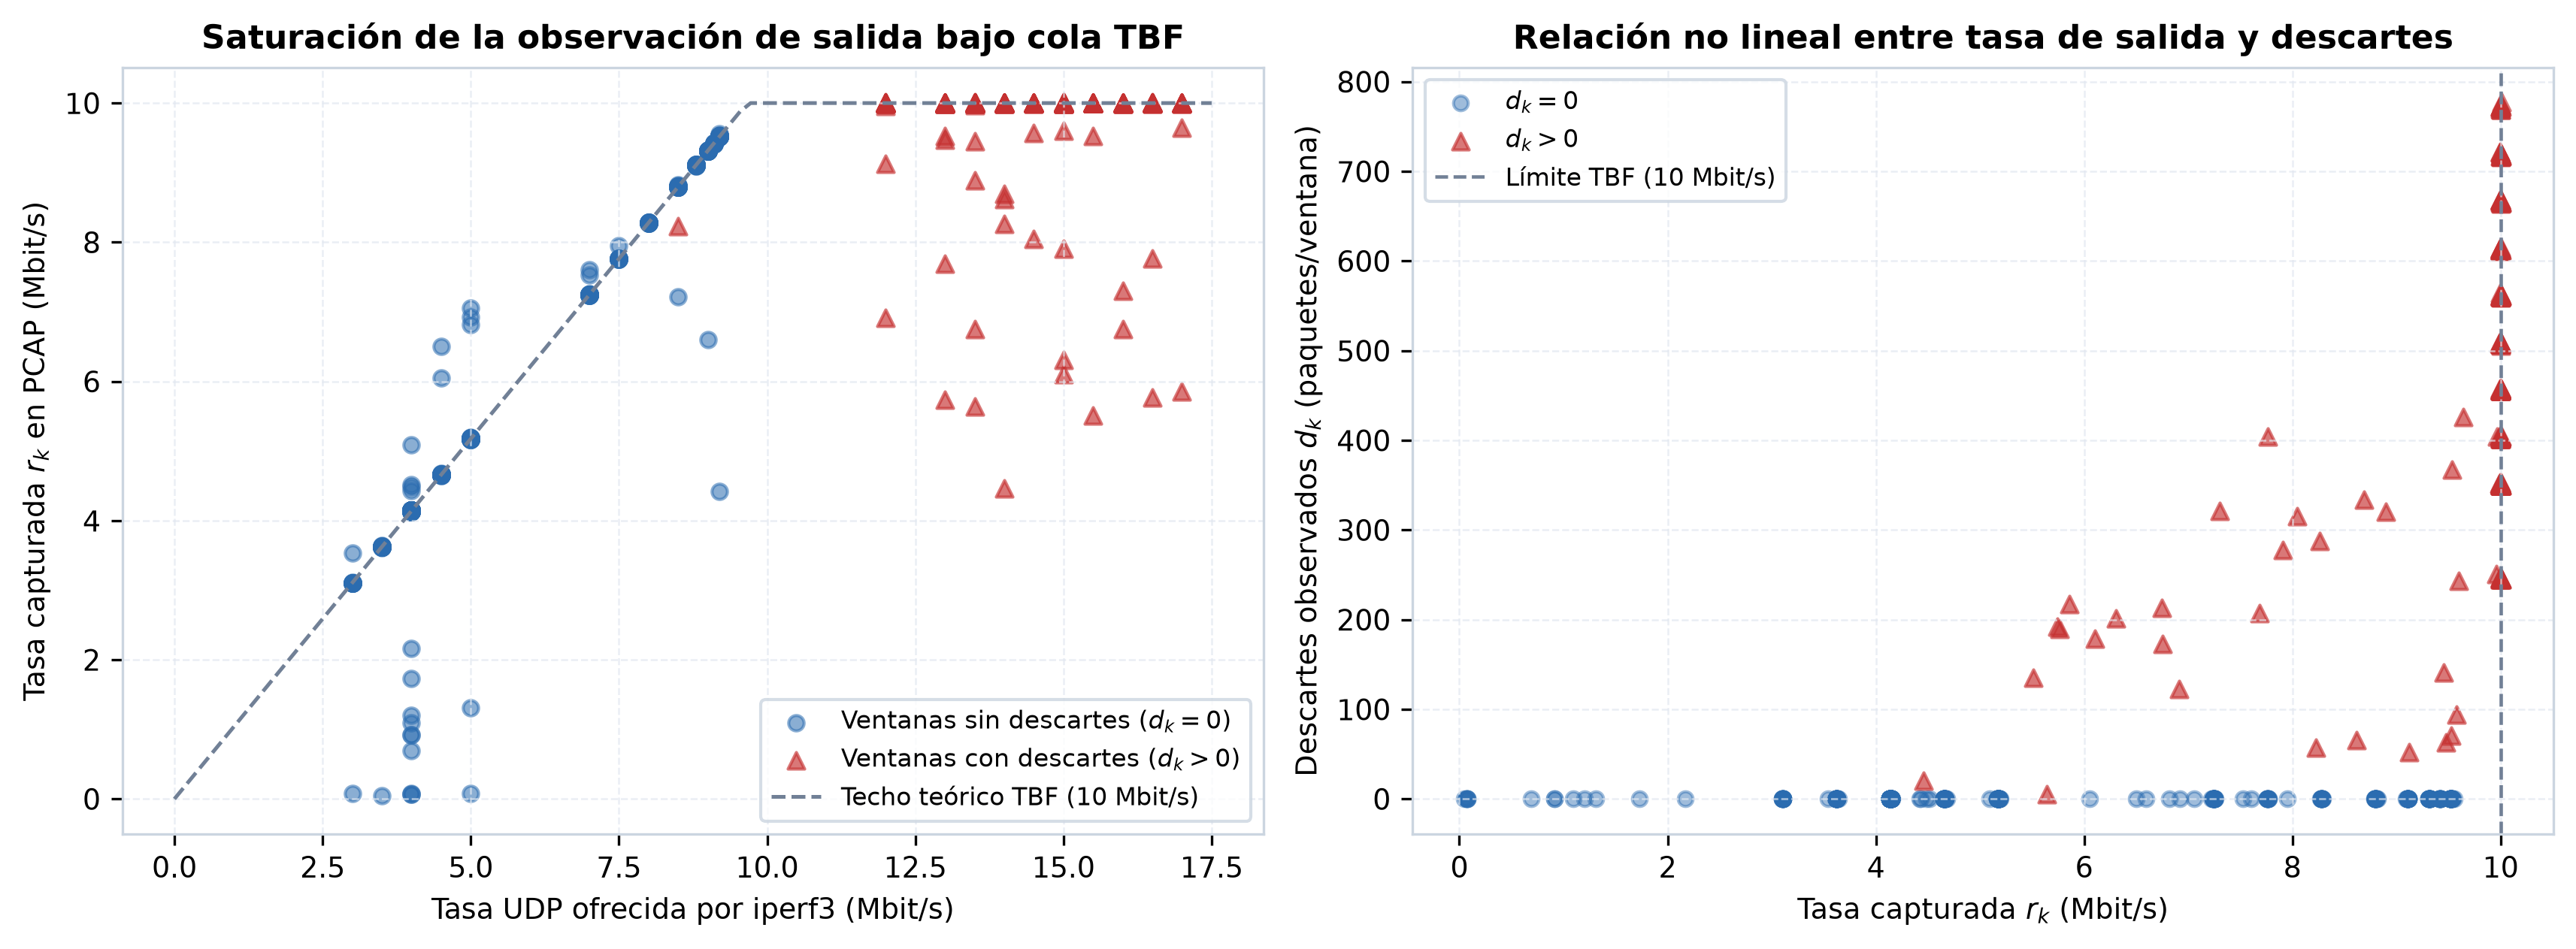

In [3]:
df_ventanas = construir_ventanas_todas(
    directorio_crudos=DATOS_CRUDOS_DIR,
    corridas=CORRIDAS_TODAS,
    ruta_salida_csv=DATOS_PROCESADOS_DIR / "ventanas.csv",
)

print(f"Total de ventanas construidas: {len(df_ventanas)}")
print(f"Ventanas válidas:              {int(df_ventanas['valida'].sum())}")
print(f"Ventanas anómalas marcadas:    {int((~df_ventanas['valida']).sum())}")
print(f"Ventanas válidas vacías (n=0): {int((df_ventanas['valida'] & (df_ventanas['n_k'] == 0)).sum())}")
print(f"Duración real delta_s: mediana={df_ventanas.loc[df_ventanas['valida'], 'delta_s'].median():.4f} s, "
      f"mín={df_ventanas.loc[df_ventanas['valida'], 'delta_s'].min():.4f} s, "
      f"máx={df_ventanas.loc[df_ventanas['valida'], 'delta_s'].max():.4f} s")

display(df_ventanas[["run_id", "ventana_idx", "delta_s", "n_k", "r_k", "d_k", "valida", "fase_interpretacion"]].head(10))

ruta_sat = graficar_saturacion_traza(df_ventanas, RESULTADOS_DIR / "saturacion_traza_tbf.png")
display(Image(filename=str(ruta_sat)))

## 3. Construcción de ejemplos supervisados y partición cronológica

Al cierre de la ventana $k$, los predictores son exclusivamente observables de la traza: $(r_k, r_{k-1}, r_{k-2}, n_k)$, y el objetivo es el conteo de descartes de la ventana siguiente $y_k = d_{k+1}$. La división conserva corridas completas y en orden de adquisición:
- **Entrenamiento:** `c01`, `c02`, `c03`
- **Validación:** `c04`
- **Prueba:** `c05`, `c06`

In [4]:
df_sup = construir_dataset_supervisado(
    df_ventanas,
    ruta_salida_csv=DATOS_PROCESADOS_DIR / "dataset_supervisado.csv",
)
df_train, df_val, df_test = dividir_particiones(df_sup)

display(resumen_particiones(df_sup))
print(f"Tamaños -> Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

,run_id,particion,ejemplos,ventanas_congestion,pct_congestion,inicios_observados,ventanas_persistencia,descartes_totales,r_k_promedio_mbps,r_k_max_mbps
0,c01,entrenamiento,102,32,31.372549,2,30,15043,7.056075,10.004990
1,c02,entrenamiento,98,32,32.653061,2,30,15043,6.705029,10.006070
2,c03,entrenamiento,109,42,38.532110,4,38,17326,7.049531,10.007669
3,c04,validacion,117,31,26.495726,2,29,15267,6.939761,10.010831
4,c05,prueba,132,33,25.000000,2,31,14609,6.924880,10.006982
5,c06,prueba,116,47,40.517241,3,44,22633,6.809929,10.007583


Tamaños -> Train: 309 | Val: 117 | Test: 248


## 4. Ajuste de `LinearRegression` y calibración en validación (`c04`)

Se entrena el modelo:

$$\hat{y}_k = \beta_0 + \beta_1 r_k + \beta_2 r_{k-1} + \beta_3 r_{k-2} + \beta_4 n_k$$

Verificamos además que aplicar `StandardScaler` ajustado únicamente con entrenamiento produce predicciones idénticas (invariancia afín de mínimos cuadrados ordinarios). Para reportar descartes pronosticados se recortan a cero los valores negativos ($\max(0, \hat{y}_k)$), manteniendo los positivos como valores continuos.

En validación (`c04`) calibramos tanto el umbral de alerta de la regresión lineal ($\theta^*$, comparado frente al umbral canónico $\theta = 1$) como el umbral de la regla simple basada en la traza ($r_k \ge \tau^*$), congelando ambos antes de evaluar prueba.

Ecuación ajustada (unidades físicas):
  y_hat_k = -224.7074 + 30.0386*r_k - 20.8376*r_{k-1} + 20.3735*r_{k-2} + 0.2450*n_k
Invariancia con StandardScaler (max |diff|): 1.96e-11
Desempeño en entrenamiento -> R²: 0.4097 | MAE (recortado): 126.25 pkt/ventana


,Variable,Coeficiente_fisico,Coeficiente_estandarizado
0,r_k,30.038637,87.549854
1,r_k_1,-20.837566,-60.732644
2,r_k_2,20.373479,59.380029
3,n_k,0.245012,72.552929


Umbral estándar de alerta:              theta  = 1.00
Umbral calibrado en validación (c04):   theta* = 295.16
Umbral regla base en validación (c04):  tau*   = 9.60 Mbit/s


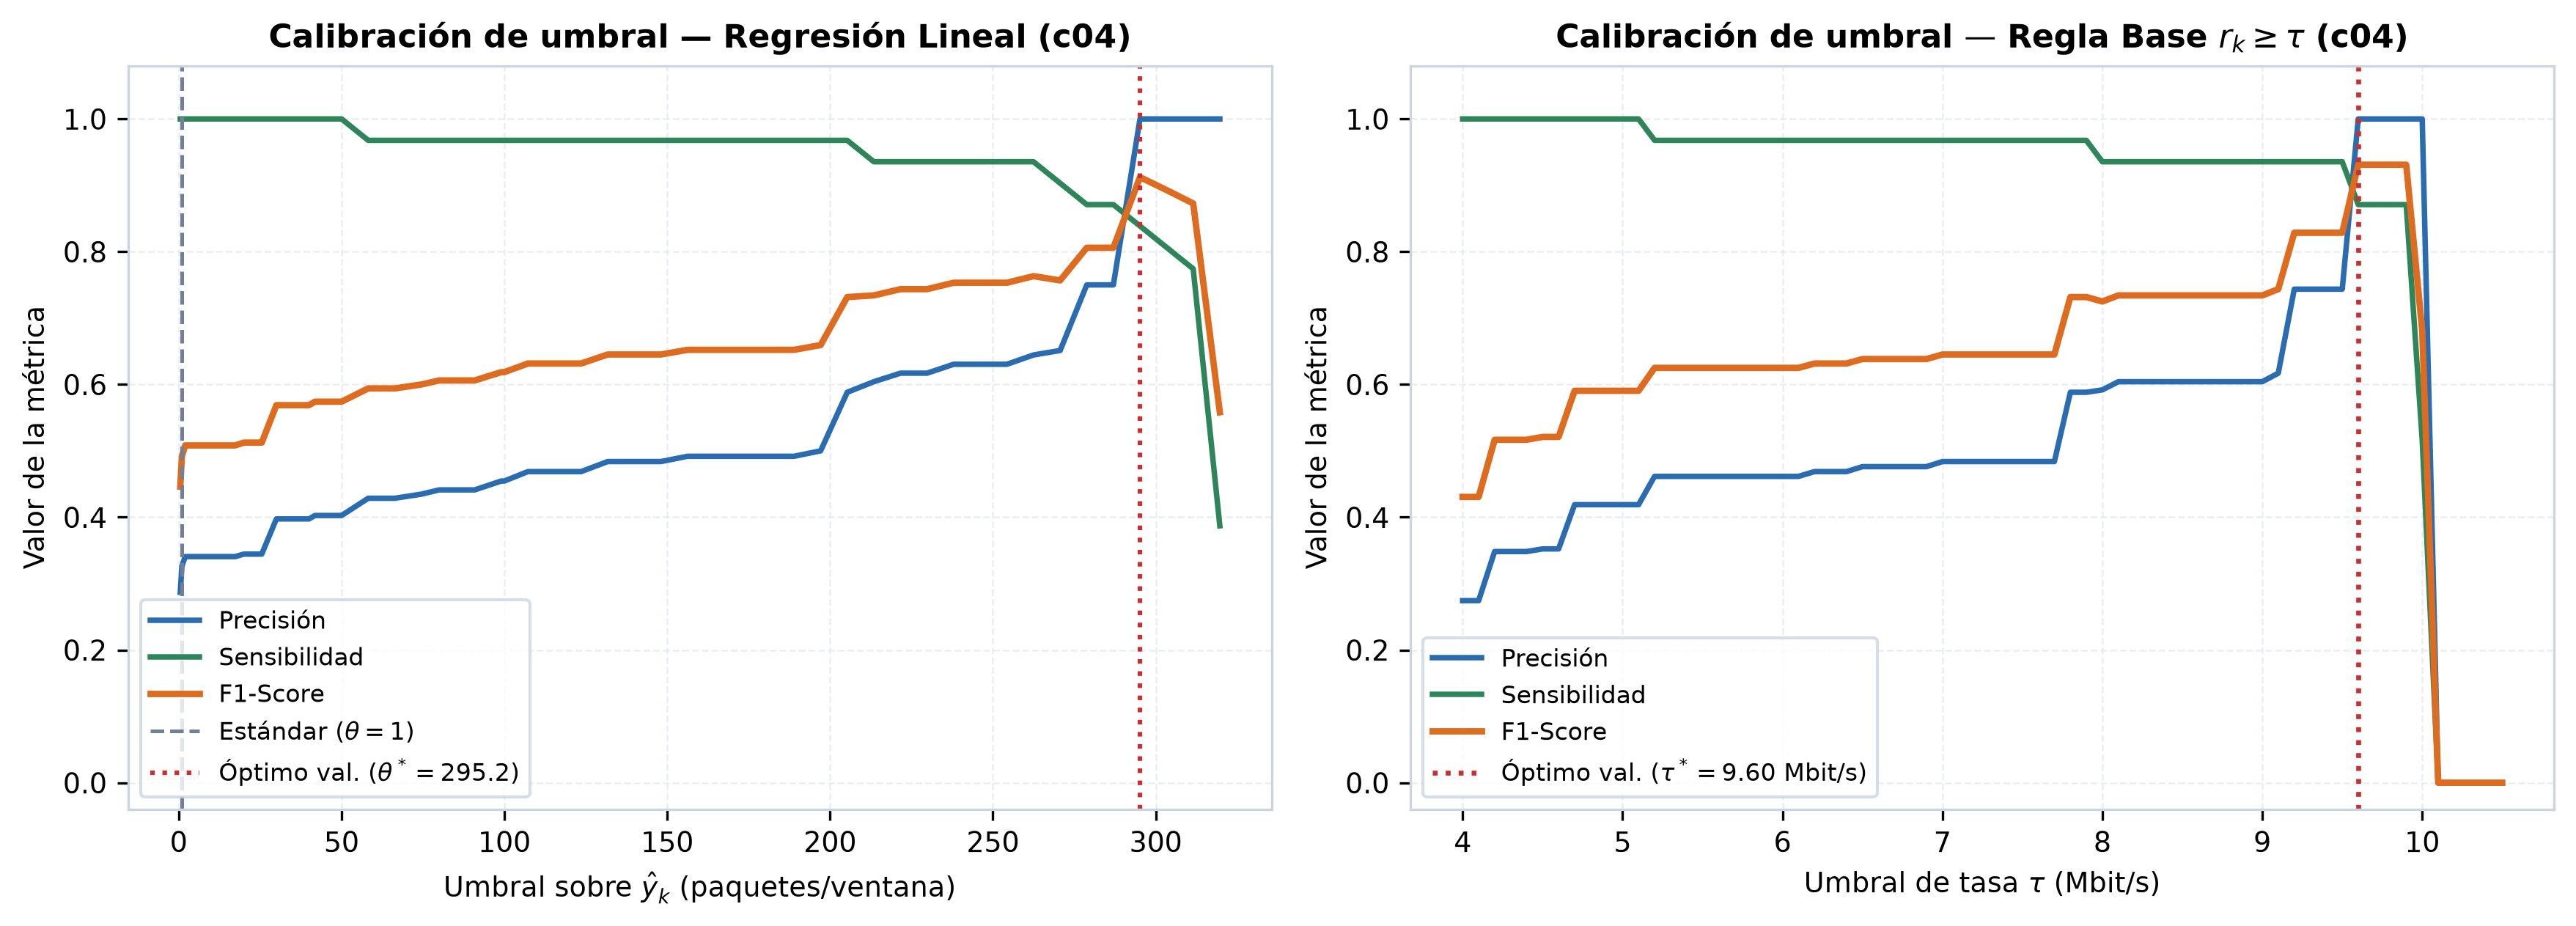

In [5]:
modelo = ModeloRegresionCongestion(
    columnas_predictoras=COLUMNAS_PREDICTORAS,
    umbral_alerta=UMBRAL_ALERTA_ESTANDAR,
)
ajuste = modelo.ajustar(df_train, col_objetivo="y_k")

print("Ecuación ajustada (unidades físicas):")
print(" ", modelo.ecuacion_texto())
print(f"Invariancia con StandardScaler (max |diff|): {ajuste.diferencia_max_escalado:.2e}")
print(f"Desempeño en entrenamiento -> R²: {ajuste.r2_entrenamiento:.4f} | MAE (recortado): {ajuste.mae_entrenamiento:.2f} pkt/ventana")

coef_df = pd.DataFrame({
    "Variable": list(ajuste.coeficientes.keys()),
    "Coeficiente_fisico": list(ajuste.coeficientes.values()),
    "Coeficiente_estandarizado": list(ajuste.coeficientes_estandarizados.values()),
})
display(coef_df)

umbral_reg_opt, tabla_cal_reg = modelo.calibrar_umbral_validacion(df_val, col_objetivo="y_k", fijar_umbral=False)
regla_base = ReglaUmbralTasa()
tau_base_opt, tabla_cal_base = regla_base.calibrar_en_validacion(df_val, col_objetivo="y_k")

print(f"Umbral estándar de alerta:              theta  = {UMBRAL_ALERTA_ESTANDAR:.2f}")
print(f"Umbral calibrado en validación (c04):   theta* = {umbral_reg_opt:.2f}")
print(f"Umbral regla base en validación (c04):  tau*   = {tau_base_opt:.2f} Mbit/s")

ruta_cal = graficar_calibracion_validacion(
    tabla_reg=tabla_cal_reg,
    umbral_reg_std=UMBRAL_ALERTA_ESTANDAR,
    umbral_reg_opt=umbral_reg_opt,
    tabla_base=tabla_cal_base,
    tau_opt=tau_base_opt,
    ruta_salida=RESULTADOS_DIR / "calibracion_validacion.png",
)
display(Image(filename=str(ruta_cal)))

## 5. Evaluación en corridas reservadas de prueba (`c05` y `c06`)

Evaluamos MAE en paquetes/ventana, matriz de confusión, precisión, sensibilidad y la capacidad de distinguir **inicio observado** ($d_k = 0, d_{k+1} > 0$) frente a **persistencia** ($d_k > 0, d_{k+1} > 0$).

Métricas de regresión en prueba (c05 + c06):
  MAE (recortado >= 0): 123.04 paquetes/ventana
  RMSE:                 178.46 paquetes/ventana
  R² (recortado):       0.4346


,Modelo,VP,FP,FN,VN,precision,sensibilidad,f1,inicios_evaluables,inicios_anticipados,inicios_omitidos,frac_inicios_anticipados,sensibilidad_persistencia
0,Regresión Lineal (theta=1),78,101,2,67,0.435754,0.9750,0.602317,5,3,2,0.6,1.000000
1,Regresión Lineal (theta*=295.16),67,0,13,168,1.000000,0.8375,0.911565,5,0,5,0.0,0.893333
2,Regla Base (r_k >= 9.60 Mbit/s),70,0,10,168,1.000000,0.8750,0.933333,5,0,5,0.0,0.933333


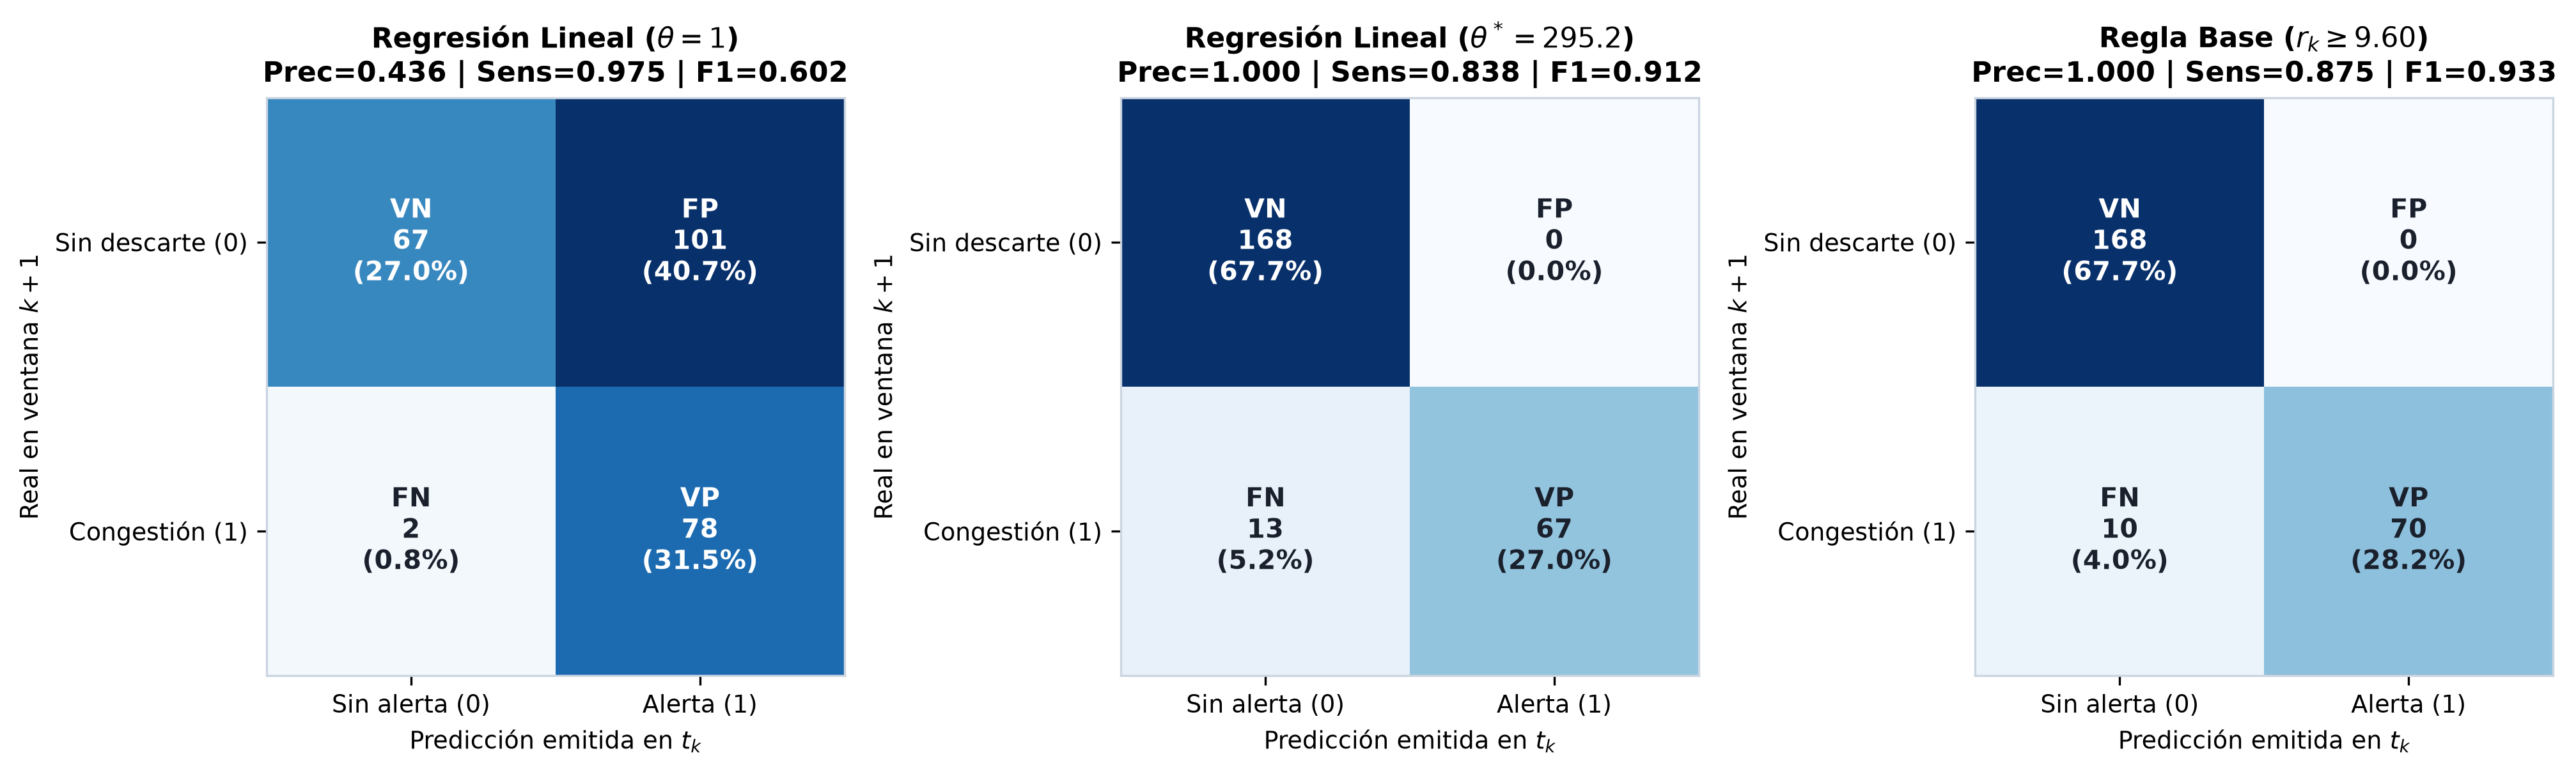

In [6]:
df_val_eval = df_val.copy()
df_val_eval["y_hat_bruto"] = modelo.predecir_bruto(df_val)
df_val_eval["y_hat_recortado"] = modelo.predecir_descartes(df_val)
df_val_eval["alerta_regresion_std"] = modelo.emitir_alerta(df_val, umbral=UMBRAL_ALERTA_ESTANDAR)
df_val_eval["alerta_regresion_opt"] = modelo.emitir_alerta(df_val, umbral=umbral_reg_opt)
df_val_eval["alerta_base"] = regla_base.emitir_alerta(df_val)

df_test_eval = df_test.copy()
df_test_eval["y_hat_bruto"] = modelo.predecir_bruto(df_test)
df_test_eval["y_hat_recortado"] = modelo.predecir_descartes(df_test)
df_test_eval["alerta_regresion_std"] = modelo.emitir_alerta(df_test, umbral=UMBRAL_ALERTA_ESTANDAR)
df_test_eval["alerta_regresion_opt"] = modelo.emitir_alerta(df_test, umbral=umbral_reg_opt)
df_test_eval["alerta_regresion"] = df_test_eval["alerta_regresion_opt"]
df_test_eval["alerta_base"] = regla_base.emitir_alerta(df_test)

reg_test = calcular_metricas_regresion(
    df_test_eval["y_k"].to_numpy(),
    df_test_eval["y_hat_recortado"].to_numpy(),
    df_test_eval["y_hat_bruto"].to_numpy(),
)
print(f"Métricas de regresión en prueba (c05 + c06):")
print(f"  MAE (recortado >= 0): {reg_test['mae_paquetes']:.2f} paquetes/ventana")
print(f"  RMSE:                 {reg_test['rmse_paquetes']:.2f} paquetes/ventana")
print(f"  R² (recortado):       {reg_test['r2_recortado']:.4f}")

al_std = calcular_metricas_alertas(df_test_eval["y_k"].to_numpy(), df_test_eval["alerta_regresion_std"].to_numpy())
al_opt = calcular_metricas_alertas(df_test_eval["y_k"].to_numpy(), df_test_eval["alerta_regresion_opt"].to_numpy())
al_base = calcular_metricas_alertas(df_test_eval["y_k"].to_numpy(), df_test_eval["alerta_base"].to_numpy())

ini_std = analizar_inicios_y_persistencia(df_test_eval, "alerta_regresion_std")
ini_opt = analizar_inicios_y_persistencia(df_test_eval, "alerta_regresion_opt")
ini_base = analizar_inicios_y_persistencia(df_test_eval, "alerta_base")

tabla_comp = construir_tabla_comparativa([
    {"Modelo": f"Regresión Lineal (theta={UMBRAL_ALERTA_ESTANDAR:g})", **al_std, **ini_std},
    {"Modelo": f"Regresión Lineal (theta*={umbral_reg_opt:.2f})", **al_opt, **ini_opt},
    {"Modelo": f"Regla Base (r_k >= {tau_base_opt:.2f} Mbit/s)", **al_base, **ini_base},
])
display(tabla_comp[[
    "Modelo", "VP", "FP", "FN", "VN", "precision", "sensibilidad", "f1",
    "inicios_evaluables", "inicios_anticipados", "inicios_omitidos",
    "frac_inicios_anticipados", "sensibilidad_persistencia",
]])

ruta_cm = graficar_matrices_confusion(
    [
        (f"Regresión Lineal ($\\theta={UMBRAL_ALERTA_ESTANDAR:g}$)", al_std),
        (f"Regresión Lineal ($\\theta^*={umbral_reg_opt:.1f}$)", al_opt),
        (f"Regla Base ($r_k \\geq {tau_base_opt:.2f}$)", al_base),
    ],
    RESULTADOS_DIR / "matrices_confusion_prueba.png",
)
display(Image(filename=str(ruta_cm)))

## 6. Gráficas temporales alineadas (ventana pronosticada $k+1$)

Cada pronóstico $\max(0, \hat{y}_k)$ y cada alerta emitida al cierre de $k$ se grafican sobre la ventana $k+1$ a la que se refieren, marcando con líneas verticales y símbolos diferenciados los inicios observados ($d_k = 0, d_{k+1} > 0$).

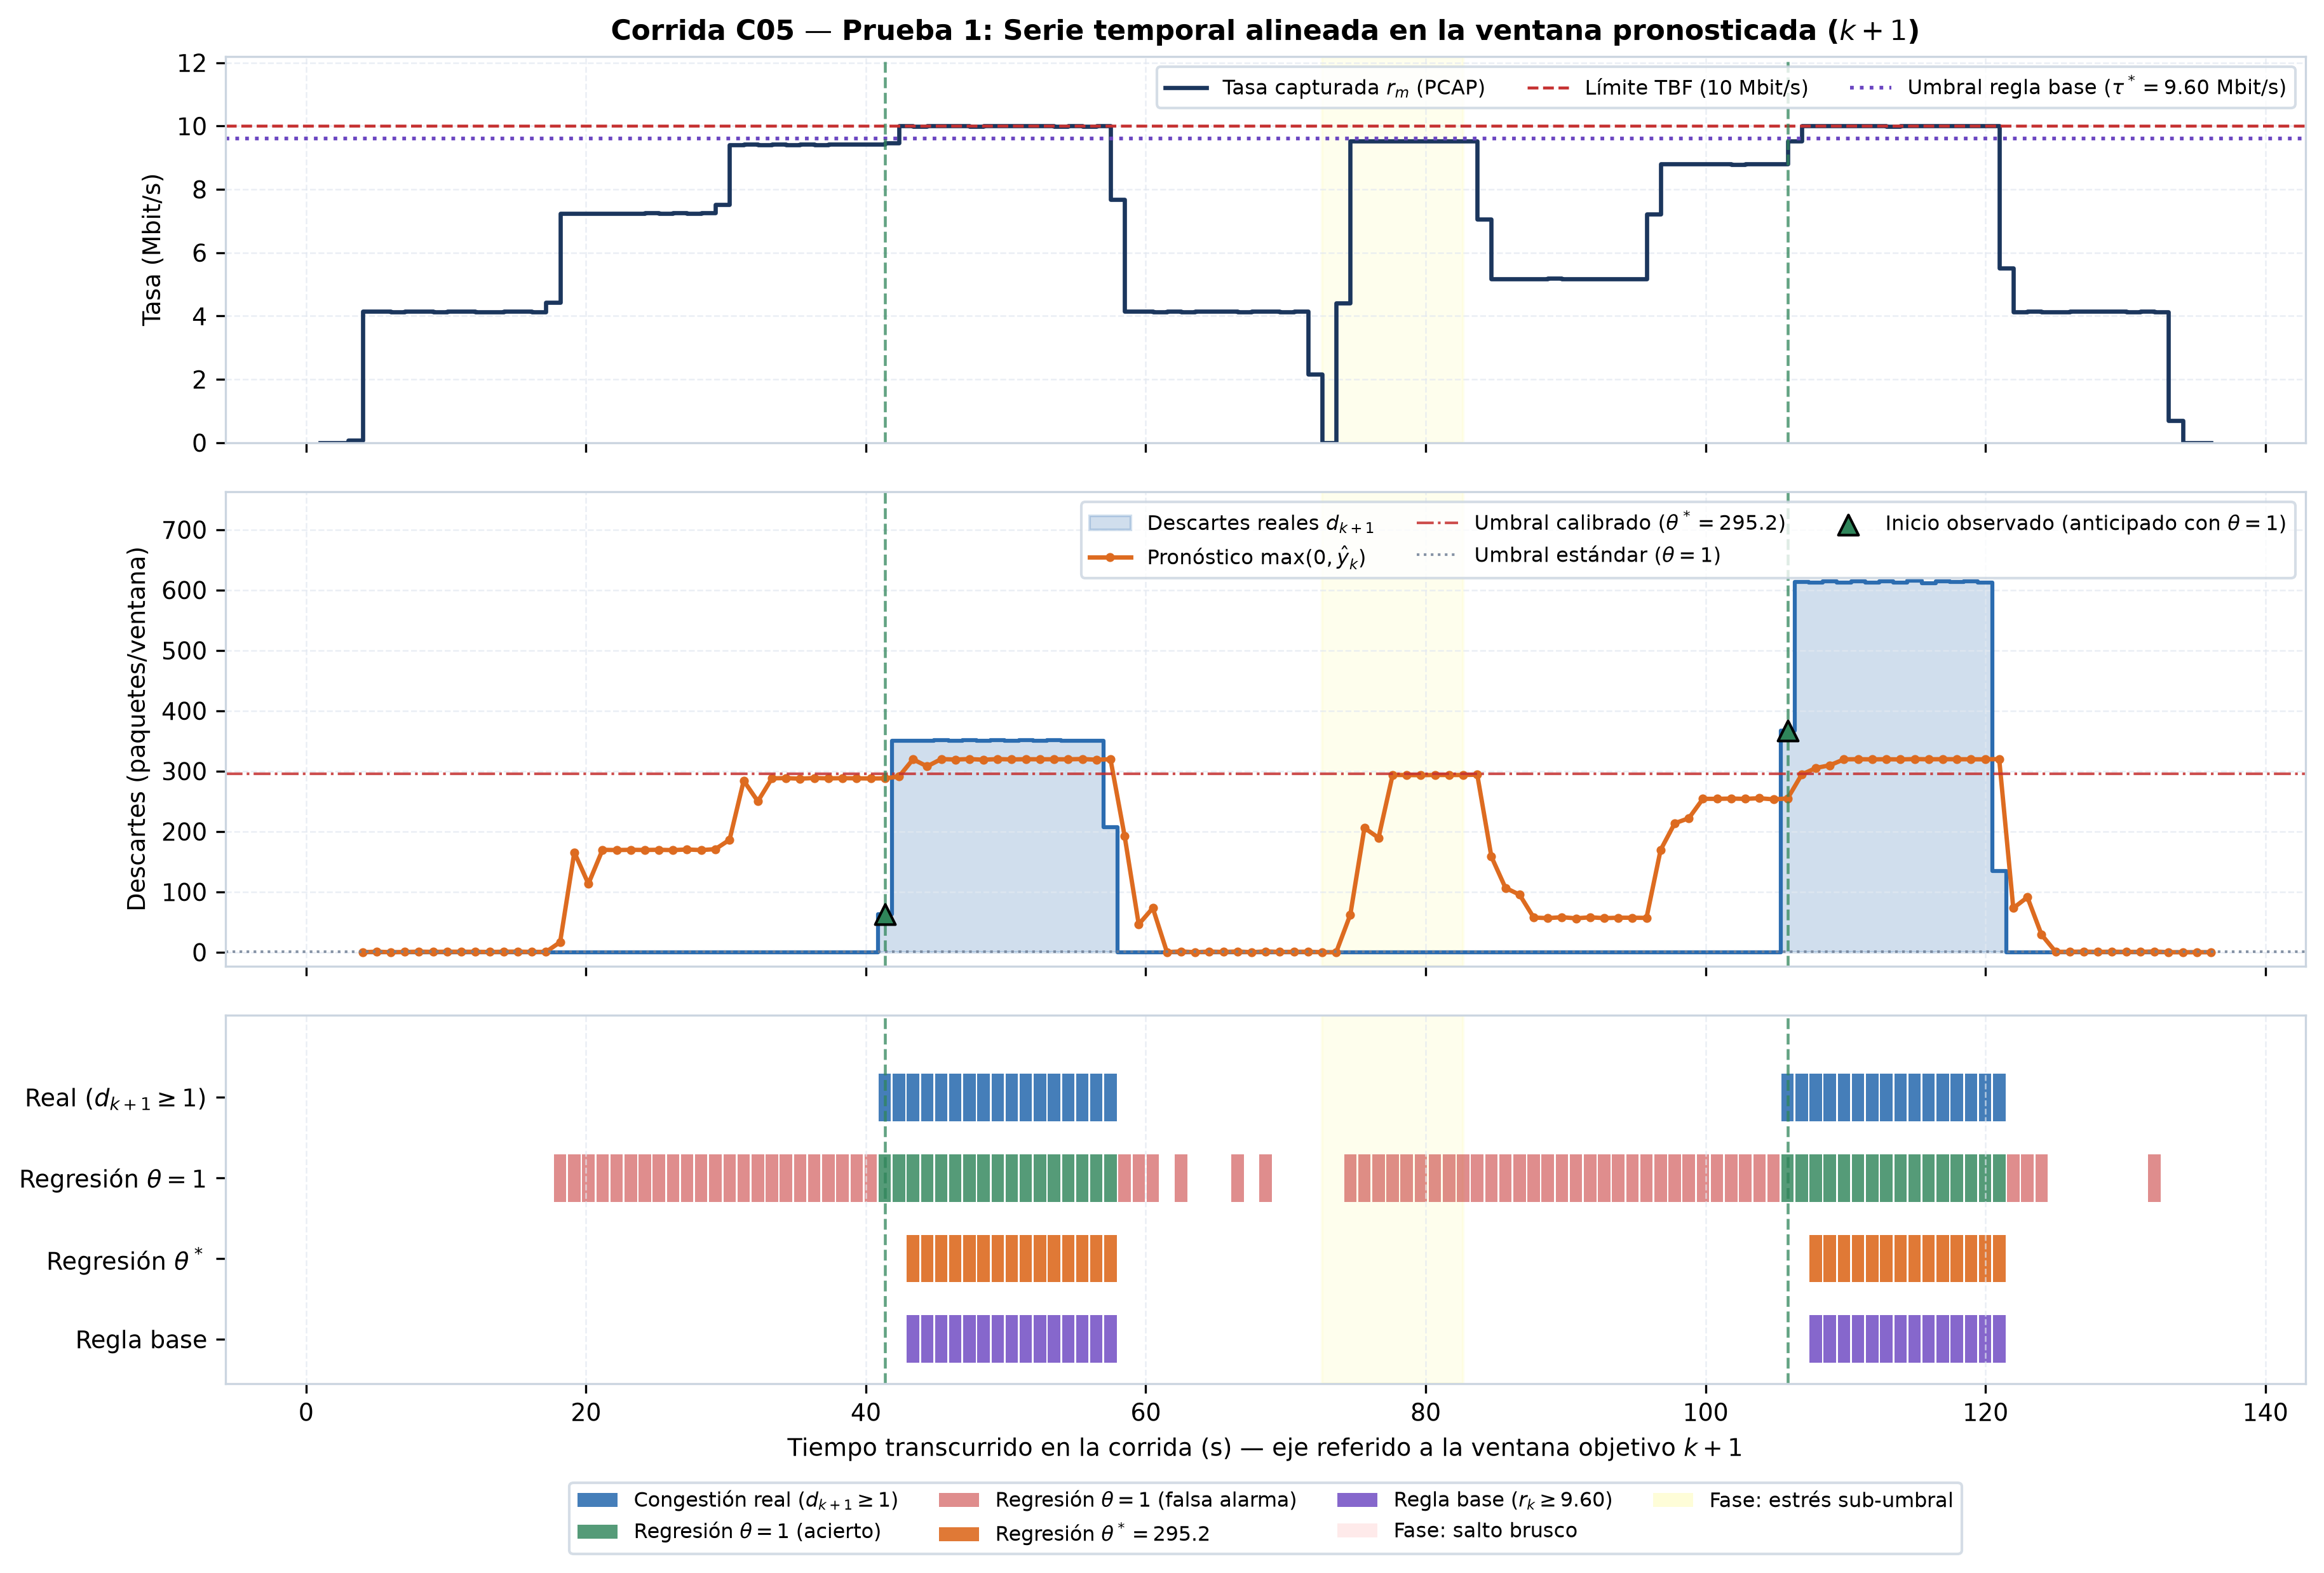

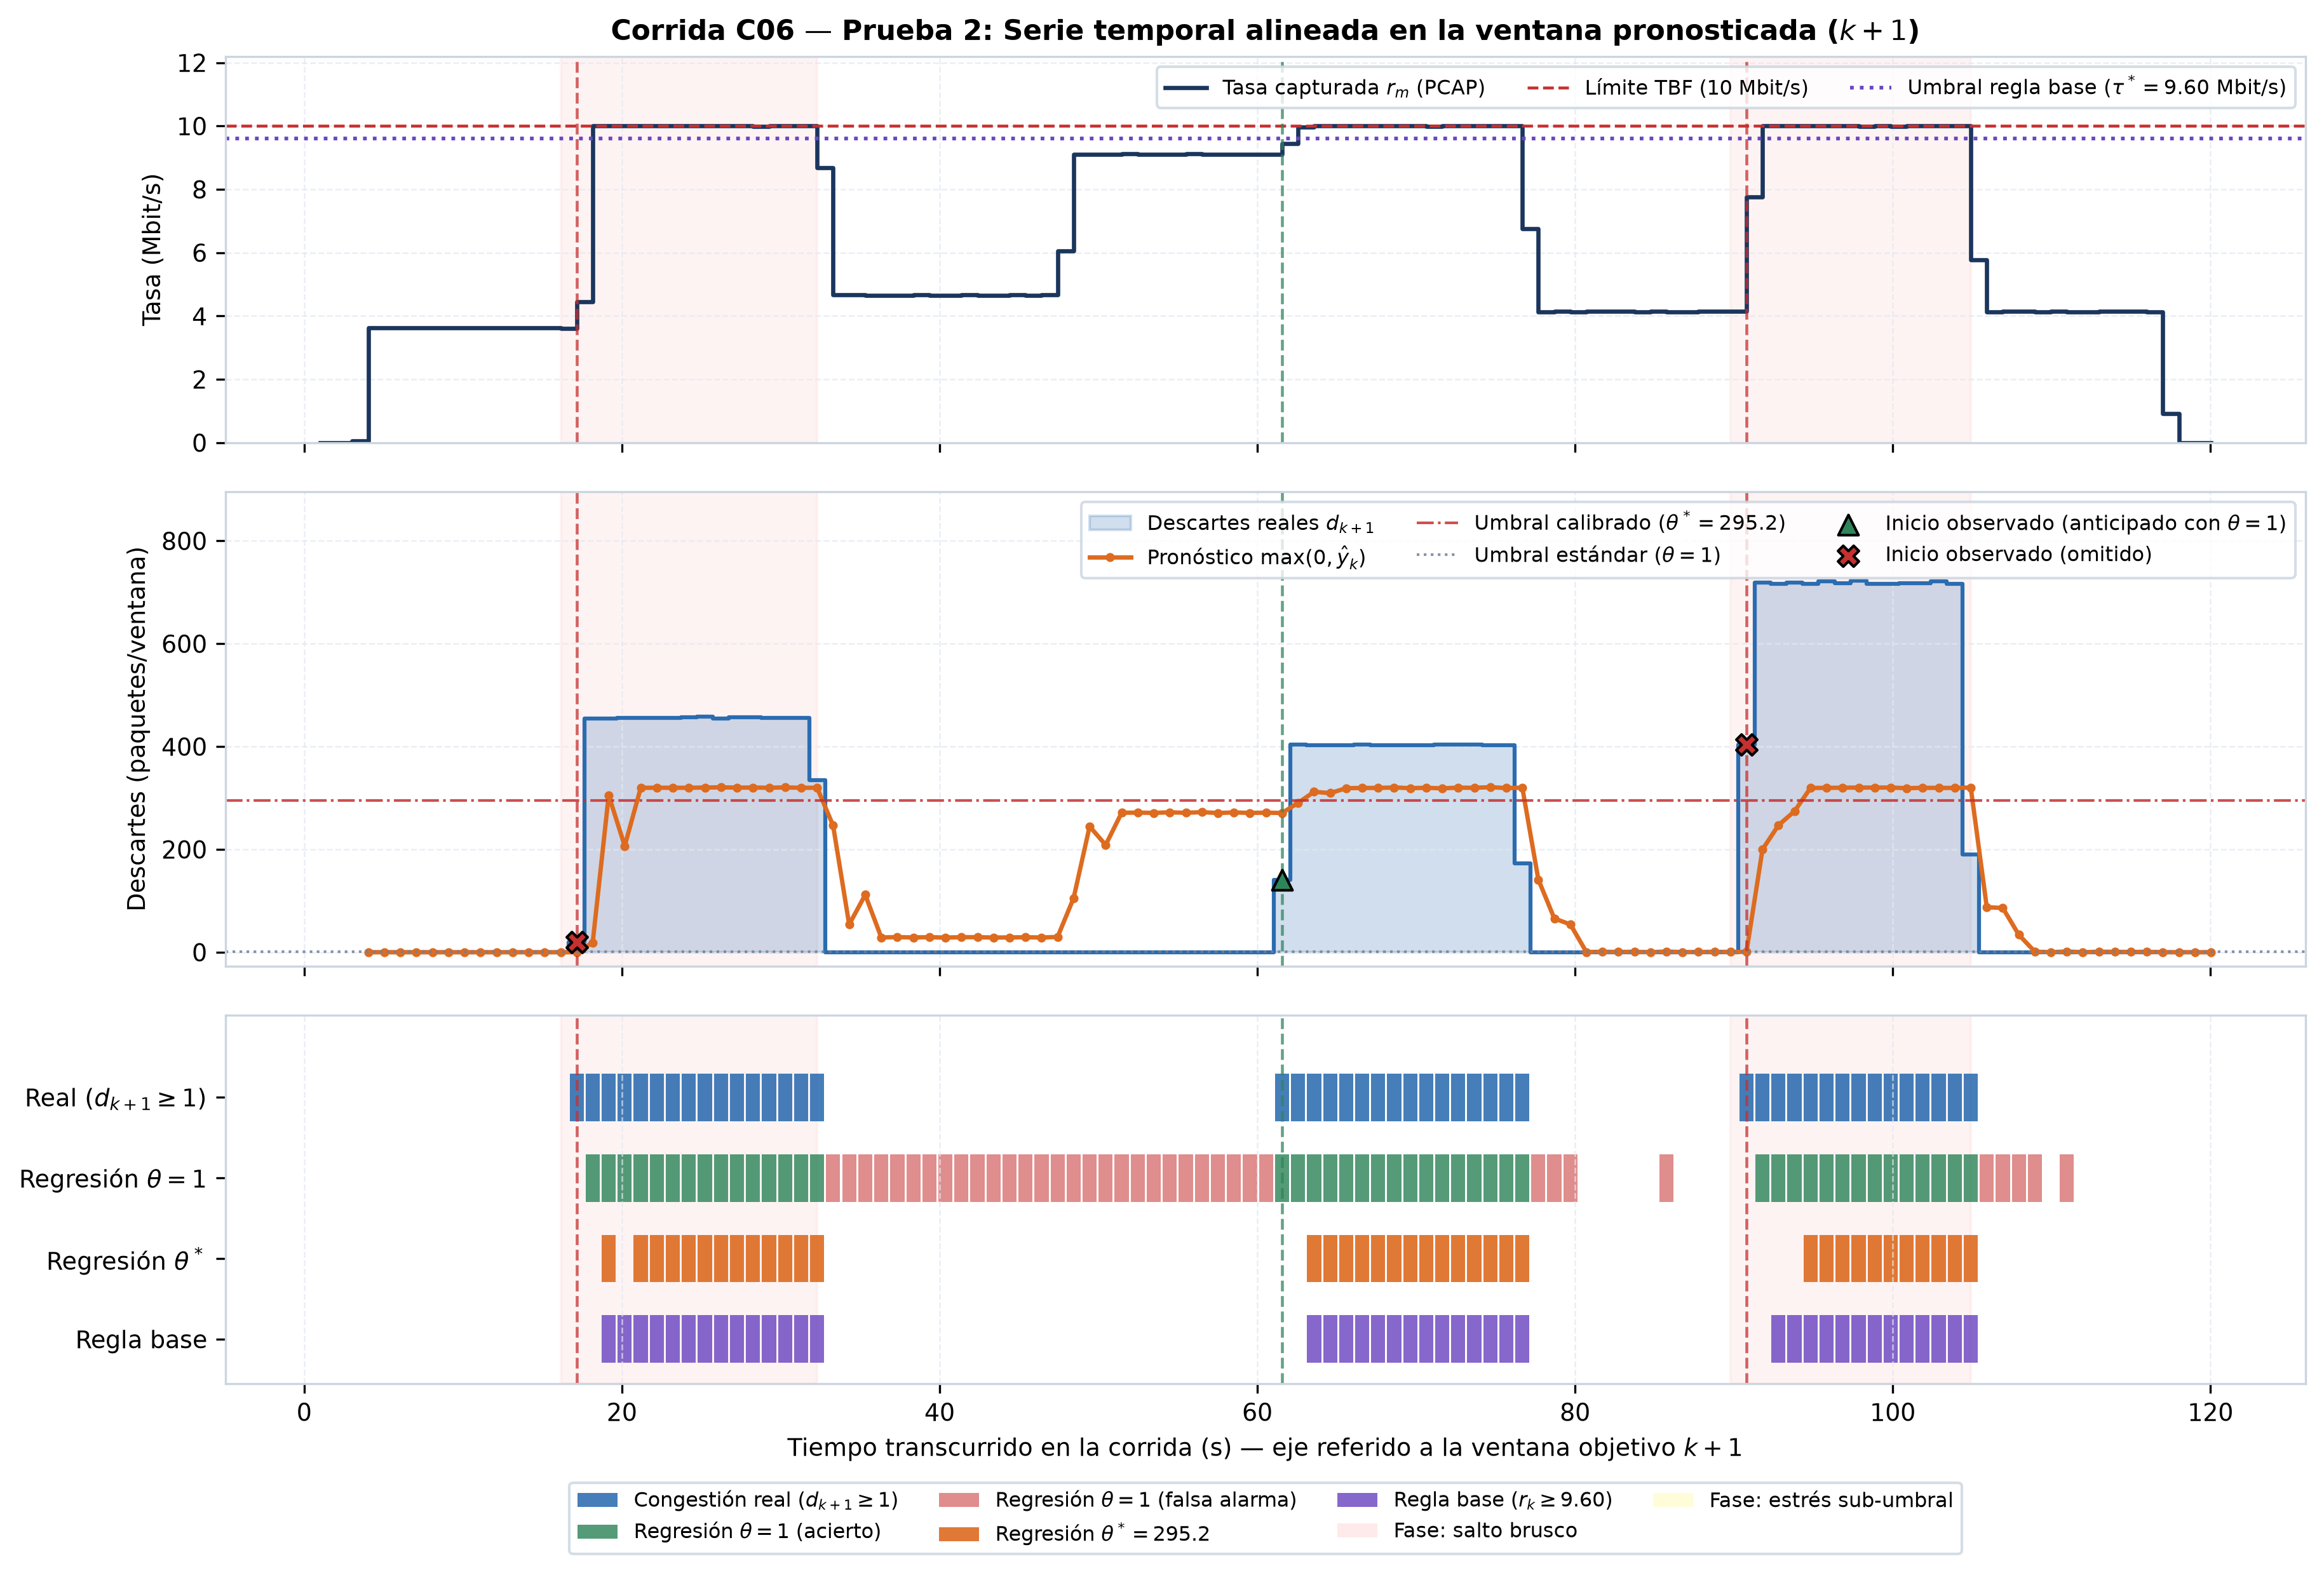

In [7]:
for rid, etiqueta in [("c05", "Prueba 1"), ("c06", "Prueba 2")]:
    ruta_fig = graficar_serie_temporal_corrida(
        df_ventanas_corrida=df_ventanas[df_ventanas["run_id"] == rid],
        df_eval_corrida=df_test_eval[df_test_eval["run_id"] == rid],
        run_id=rid,
        tau_base_mbps=tau_base_opt,
        umbral_reg=umbral_reg_opt,
        ruta_salida=RESULTADOS_DIR / f"serie_temporal_{rid}.png",
        col_alerta_reg="alerta_regresion_opt",
        titulo_extra=etiqueta,
    )
    display(Image(filename=str(ruta_fig)))

## 7. Inicio vs. persistencia, rampas vs. saltos bruscos y estudio de casos concretos

=== Inicios por tipo de transición (Regresión Lineal umbral estándar θ=1) ===


,tipo_transicion_k1,inicios_evaluables,inicios_anticipados,inicios_omitidos,frac_anticipados,r_k_media_previa_mbps,y_hat_media
0,rampa,3,3,0,1.0,9.106464,271.147577
1,salto_brusco,2,0,2,0.0,3.877591,0.321436


=== Inicios por tipo de transición (Regresión Lineal calibrada θ*) ===


,tipo_transicion_k1,inicios_evaluables,inicios_anticipados,inicios_omitidos,frac_anticipados,r_k_media_previa_mbps,y_hat_media
0,rampa,3,0,3,0.0,9.106464,271.147577
1,salto_brusco,2,0,2,0.0,3.877591,0.321436


=== Inicios por tipo de transición (Regla Base) ===


,tipo_transicion_k1,inicios_evaluables,inicios_anticipados,inicios_omitidos,frac_anticipados,r_k_media_previa_mbps,y_hat_media
0,rampa,3,0,3,0.0,9.106464,271.147577
1,salto_brusco,2,0,2,0.0,3.877591,0.321436


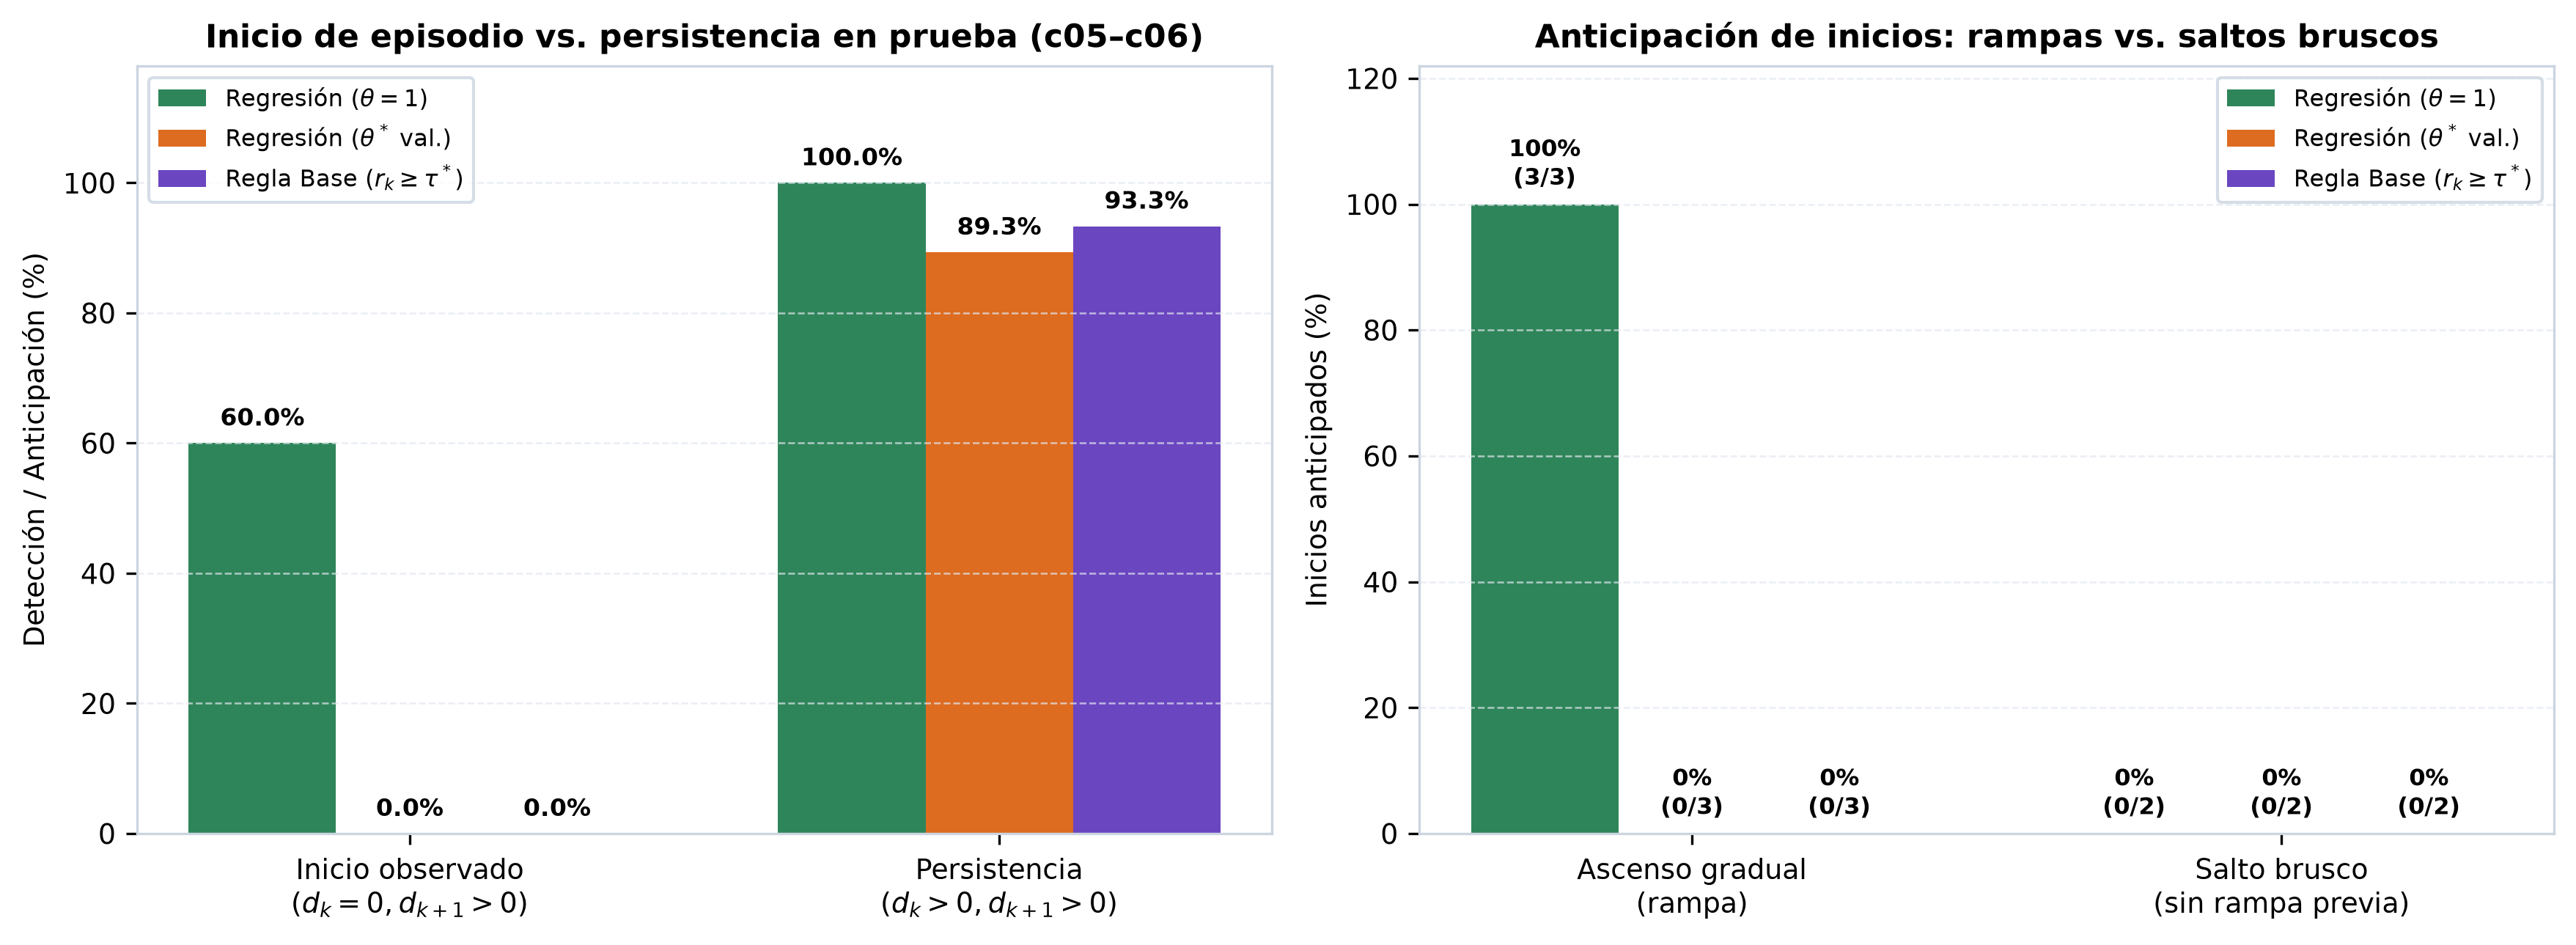


=== Catálogo de todos los inicios observados en prueba (c05–c06) ===


,run_id,ventana_idx_k1,t_rel_fin_k1_s,tipo_transicion_k1,r_k_1,r_k,n_k,y_k,y_hat_recortado,estado_inicio
0,c05,41,41.354818,rampa,9.419080,9.415753,956,63,288.030836,Omitido
1,c05,105,105.863372,rampa,8.793456,8.798586,893,367,254.684590,Omitido
2,c06,17,17.155325,salto_brusco,3.628465,3.613901,367,20,0.000000,Omitido
3,c06,61,61.555776,rampa,9.105629,9.105052,923,141,270.727304,Omitido
4,c06,90,90.794398,salto_brusco,4.142290,4.141282,420,404,0.642871,Omitido



=== Casos de falsa alarma analizados (2) ===

--- Falsa alarma #1 ---


,run_id,ventana_idx,ventana_idx_k1,r_k,n_k,d_k,y_k,y_hat_recortado,fase_k1_interpretacion,es_evento_foco
77,c05,80,81,9.522834,966,0,0,293.591800,Estres_subumbral,False
78,c05,81,82,9.522328,966,0,0,293.546970,Estres_subumbral,False
79,c05,82,83,9.527971,967,0,0,294.018073,Recuperacion_2,True
80,c05,83,84,7.055198,717,0,0,158.358329,Recuperacion_2,False
81,c05,84,85,5.176777,525,0,0,106.532257,Recuperacion_2,False



--- Falsa alarma #2 ---


,run_id,ventana_idx,ventana_idx_k1,r_k,n_k,d_k,y_k,y_hat_recortado,fase_k1_interpretacion,es_evento_foco
71,c05,74,75,9.521611,966,0,0,205.911994,Estres_subumbral,False
72,c05,75,76,9.515906,966,0,0,189.440466,Estres_subumbral,False
73,c05,76,77,9.523758,966,0,0,293.755414,Estres_subumbral,True
74,c05,77,78,9.521731,966,0,0,293.414658,Estres_subumbral,False
75,c05,78,79,9.519718,965,0,0,293.311418,Estres_subumbral,False



=== Casos de inicio omitido analizados (2) ===

--- Inicio omitido #1 ---


,run_id,ventana_idx,ventana_idx_k1,r_k,n_k,d_k,y_k,y_hat_recortado,fase_k1_interpretacion,tipo_transicion_k1,es_evento_foco
216,c06,87,88,4.140765,420,0,0,0.726272,Recuperacion_2,recuperacion,False
217,c06,88,89,4.142290,420,0,0,0.577409,Recuperacion_2,recuperacion,False
218,c06,89,90,4.141282,420,0,404,0.642871,Sobrecarga_3,salto_brusco,True
219,c06,90,91,7.765469,789,404,719,199.970204,Sobrecarga_3,salto_brusco,False
220,c06,91,92,10.003515,1015,719,717,247.031081,Sobrecarga_3,salto_brusco,False



--- Inicio omitido #2 ---


,run_id,ventana_idx,ventana_idx_k1,r_k,n_k,d_k,y_k,y_hat_recortado,fase_k1_interpretacion,tipo_transicion_k1,es_evento_foco
99,c05,102,103,8.812070,894,0,0,255.091124,Ascenso_3,rampa,False
100,c05,103,104,8.793456,891,0,0,253.224588,Ascenso_3,rampa,False
101,c05,104,105,8.798586,893,0,367,254.684590,Sobrecarga_2,rampa,True
102,c05,105,106,9.530132,967,367,613,294.304022,Sobrecarga_2,rampa,False
103,c05,106,107,10.002652,1015,613,612,305.119363,Sobrecarga_2,rampa,False


In [8]:
rs_std = analizar_rampas_vs_saltos(df_test_eval, "alerta_regresion_std")
rs_opt = analizar_rampas_vs_saltos(df_test_eval, "alerta_regresion_opt")
rs_base = analizar_rampas_vs_saltos(df_test_eval, "alerta_base")

print("=== Inicios por tipo de transición (Regresión Lineal umbral estándar θ=1) ===")
display(rs_std)
print("=== Inicios por tipo de transición (Regresión Lineal calibrada θ*) ===")
display(rs_opt)
print("=== Inicios por tipo de transición (Regla Base) ===")
display(rs_base)

ruta_ip = graficar_inicios_y_persistencia(
    resumen_std=ini_std,
    resumen_opt=ini_opt,
    resumen_base=ini_base,
    df_rs_std=rs_std,
    df_rs_opt=rs_opt,
    df_rs_base=rs_base,
    ruta_salida=RESULTADOS_DIR / "inicios_vs_persistencia.png",
)
display(Image(filename=str(ruta_ip)))

print("\n=== Catálogo de todos los inicios observados en prueba (c05–c06) ===")
tabla_inicios = extraer_tabla_inicios(df_test_eval, col_alerta="alerta_regresion_opt")
display(tabla_inicios[[
    "run_id", "ventana_idx_k1", "t_rel_fin_k1_s", "tipo_transicion_k1",
    "r_k_1", "r_k", "n_k", "y_k", "y_hat_recortado", "estado_inicio",
]])

casos_fa = extraer_casos_falsa_alarma(df_test_eval, col_alerta="alerta_regresion_opt", max_casos=2)
if not casos_fa:
    casos_fa = extraer_casos_falsa_alarma(df_test_eval, col_alerta="alerta_regresion_std", max_casos=2)
print(f"\n=== Casos de falsa alarma analizados ({len(casos_fa)}) ===")
for idx, df_caso in enumerate(casos_fa, 1):
    print(f"\n--- Falsa alarma #{idx} ---")
    display(df_caso[["run_id", "ventana_idx", "ventana_idx_k1", "r_k", "n_k", "d_k", "y_k", "y_hat_recortado", "fase_k1_interpretacion", "es_evento_foco"]])

casos_omi = extraer_casos_inicio_omitido(df_test_eval, col_alerta="alerta_regresion_opt", max_casos=2)
print(f"\n=== Casos de inicio omitido analizados ({len(casos_omi)}) ===")
for idx, df_caso in enumerate(casos_omi, 1):
    print(f"\n--- Inicio omitido #{idx} ---")
    display(df_caso[["run_id", "ventana_idx", "ventana_idx_k1", "r_k", "n_k", "d_k", "y_k", "y_hat_recortado", "fase_k1_interpretacion", "tipo_transicion_k1", "es_evento_foco"]])

## 8. Conclusiones y limitaciones físicas del problema

1. **Observación post-cola en la interfaz de salida:** dado que `tcpdump` captura las tramas salientes después del moldeado de la cola TBF, la tasa capturada $r_k$ se satura alrededor de 10 Mbit/s incluso cuando `iperf3` ofrece 13–17 Mbit/s. Esto comprime la señal en régimen de sobrecarga e impide que un modelo lineal distinga linealmente magnitudes severas de descarte sin variables adicionales de estado de cola.
2. **Inicio frente a persistencia:** la sensibilidad suele ser considerablemente más alta en ventanas de **persistencia** ($d_k > 0, d_{k+1} > 0$, donde $r_k$ ya se encuentra pegada al techo de 10 Mbit/s) que en **inicios observados** ($d_k = 0, d_{k+1} > 0$).
3. **Rampas frente a saltos bruscos:** durante ascensos graduales, el crecimiento progresivo de $r_k$ (8–9.2 Mbit/s) y sus rezagos aporta señal previa antes del primer descarte; en cambio, ante un salto brusco desde carga baja (~3.5–4.5 Mbit/s) hasta sobrecarga (14–16.5 Mbit/s), no existe información precursora en la traza al cierre de $k$, por lo que la omisión del inicio constituye un límite causal inherente a la señal observable.
4. **Indeterminación sub-ventana:** la agregación por intervalos cercanos a 1 s indica que ocurrirá al menos un descarte en la ventana siguiente, pero no determina el instante exacto dentro del segundo en que se produce el primer paquete descartado.